# Qdislib — 07 · Cutting a quantum image, distributed with PyCOMPSs

**A handful of qubits holds a whole image.** With QPIE (Quantum Probability
Image Encoding) an `n`-qubit state is a probability distribution over `2**n`
bitstrings — read each bitstring as a **pixel address** and its probability as
the pixel **brightness**. So **4 qubits index all 16 rows** (`2**4 = 16`), 4
more index all 16 columns, and just **8 qubits encode the whole 16×16 = 256
pixel image** — an *exponential* packing (8 qubits for 256 pixels).

That packing is exactly *why you'd cut*: an image that needs 8 qubits can be
run as **two independent 4-qubit halves** — the rows and the columns — and
reassembled. In this notebook you encode an image, **entangle** the two
registers, **cut the 8-qubit circuit into two 4-qubit pieces**, and rebuild the
full image with `gate_cutting_sampling` (which reconstructs the whole output
*distribution*, not just one number). **The whole notebook runs under
PyCOMPSs**, so the subcircuits sample in parallel.

Here's the story you'll build — encode → entangle → cut & reconstruct:

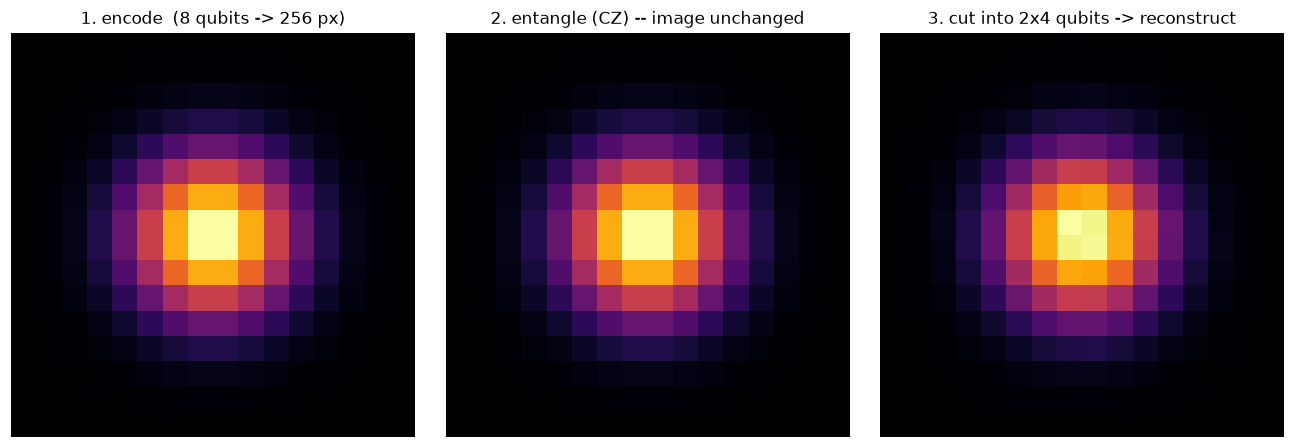

Look for the **🔧 Your turn** cells: change a line, re-run, watch it change.

## Start the PyCOMPSs runtime

This starts the COMPSs runtime **for the whole notebook**: from here on every
`gate_cutting_sampling` call submits its subcircuits as parallel COMPSs
`@task`s and gathers the results for you — the code is identical to running it
serially. `graph=True` records the task graph under `$HOME/.COMPSs/…/monitor/`
(render it with `compss_gengraph`). Run this notebook top to bottom; the very
last cell stops the runtime.

In [ ]:
import pycompss.interactive as ipycompss
ipycompss.start(graph=True, monitor=1000)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
import qiskit.quantum_info as qi
import Qdislib as qd

N_ROW = N_COL = 4          # 4 row qubits + 4 column qubits
N = N_ROW + N_COL          # -> 16 x 16 = 256 pixels


def brightness_profile(n_bits, center, width):
    """Amplitudes whose |.|**2 form a Gaussian bump over 2**n_bits values."""
    x = np.arange(2 ** n_bits)
    p = np.exp(-0.5 * ((x - center) / width) ** 2)
    return np.sqrt(p / p.sum())


def to_image(distribution):
    """{bitstring: probability}  ->  16x16 array (row bits | column bits)."""
    image = np.zeros((2 ** N_ROW, 2 ** N_COL))
    for bitstring, prob in distribution.items():
        row = int(bitstring[:N_ROW][::-1], 2)
        col = int(bitstring[N_ROW:][::-1], 2)
        image[row, col] += prob
    return image


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img, cmap='inferno'); ax.set_title(title); ax.axis('off')
    plt.show()

## 1. Encode the image  ·  *4 qubits → 16 positions*

We load a **row** brightness profile onto the 4 row qubits and a **column**
profile onto the 4 column qubits (`StatePreparation`). Each 4-qubit register
spans all `2**4 = 16` positions along its axis — so **8 qubits hold the whole
16×16 image**. Preparing the two registers independently makes a smooth,
separable blob (`row_profile ⊗ column_profile`).

In [ ]:
def encode_image(entangle):
    qc = QuantumCircuit(N)
    # QPIE: load the row and column brightness profiles (a smooth Gaussian bump).
    qc.append(StatePreparation(brightness_profile(N_ROW, center=7.5, width=2.2)),
              range(N_ROW))
    qc.append(StatePreparation(brightness_profile(N_COL, center=7.5, width=2.2)),
              range(N_ROW, N))
    qc = transpile(qc, basis_gates=['ry', 'rz', 'cx', 'cz', 'h', 'x'],
                   optimization_level=1)
    if entangle:
        # ENTANGLE (step 2): couple the two registers with two CZ gates, each
        # tying a row qubit to a column qubit. These are our cut points.
        qc.cz(0, N_ROW)
        qc.cz(N_ROW - 1, N - 1)
    return qc


def exact_image(qc):
    """The true image, from the exact statevector (our ground truth)."""
    probs = np.abs(qi.Statevector(qc).data) ** 2
    dist = {''.join(str((i >> q) & 1) for q in range(N)): probs[i]
            for i in range(2 ** N)}
    return to_image(dist)


show([exact_image(encode_image(entangle=False))], ['encoded image (a blob)'])

## 2. Entangle the rows and columns

Now we couple the two registers with two `CZ` (controlled-Z) gates, each from
a **row qubit to a column qubit**. This genuinely **entangles** the 8-qubit
state — it is no longer a product of an independent row state and column
state, so you can't just run the two 4-qubit halves separately and multiply.

A `CZ` only adds a **phase**, so it leaves the measurement probabilities — the
**image** — exactly unchanged. That's the point of this demo: the picture
stays put while the circuit becomes entangled, so when we cut and rebuild it,
a correct reconstruction must return the **identical** blob. (These two `CZ`
gates are the cut points in step 3.)

In [ ]:
show([exact_image(encode_image(entangle=False)),
      exact_image(encode_image(entangle=True))],
     ['before (separable)', 'after CZ (entangled -- image unchanged)'])

### 🔧 Your turn (1)

Change the **blob**: move its center or make it wider/narrower, then re-run.
Try `center=4.0` (top-left) or `width=1.0` (sharper).

In [ ]:
def brightness_profile(n_bits, center, width):        # <-- edit center / width
    x = np.arange(2 ** n_bits)
    p = np.exp(-0.5 * ((x - center) / width) ** 2)
    return np.sqrt(p / p.sum())

show([exact_image(encode_image(entangle=True))], ['your image'])

## 3. The image is an 8-qubit circuit — cut it in two

Suppose our device only has ~4 qubits. `find_cut` looks for a good place to
split the circuit; here it finds the two row↔column `CZ` gates, which separate
the **row half** from the **column half**.

In [ ]:
entangled = encode_image(entangle=True)
cut = qd.find_cut(entangled, gate_cut=True, wire_cut=False, max_qubits=N_ROW)
print('cut gates:', cut)   # the two row<->column entanglers

## 4. Reconstruct the image by sampling the pieces — in parallel

`gate_cutting_sampling` samples each subcircuit independently and recombines
them (via the gate-cut quasiprobability decomposition) into the **full output
distribution** — the reconstructed image. Two cuts means `6**2 = 36` subcircuit
configurations, each a small 4-qubit circuit. **Under PyCOMPSs these
subcircuits sample in parallel** across the available workers — the call is
exactly the same as serial.

In [ ]:
distribution = qd.gate_cutting_sampling(entangled, cut, shots=200_000,
                                        software='qiskit')
reconstructed = to_image(distribution)

show([exact_image(entangled), reconstructed],
     ['exact image', 'reconstructed from the 2 halves'])

tvd = 0.5 * np.abs(exact_image(entangled) - reconstructed).sum()
print(f'total-variation distance vs exact: {tvd:.4f}   (~shot noise)')

### 🔧 Your turn (2)

Fewer shots ⇒ a noisier reconstruction. Re-run with `shots=20_000` and compare
the image and the TVD. (Sampling reconstruction carries a quasiprobability
overhead, so it needs more shots than a plain expectation value.)

In [ ]:
distribution = qd.gate_cutting_sampling(entangled, cut, shots=20_000,   # <-- change
                                        software='qiskit')
noisy = to_image(distribution)
show([reconstructed, noisy], ['200k shots', '20k shots'])
print('TVD:', round(0.5 * np.abs(exact_image(entangled) - noisy).sum(), 4))

## Recap & bonus

You encoded a 256-pixel image in **8 qubits**, entangled the row and column
registers with `CZ`, **cut the 8-qubit circuit into two 4-qubit halves**, and
rebuilt the *full image distribution* by sampling — all running distributed
under PyCOMPSs — recovering the identical blob.

**🔧 Bonus:** bump the resolution to `32×32` with `N_ROW = N_COL = 5` (re-run
from the setup cell). The circuit grows to 10 qubits and each half to 5 — but
it's still just **two cuts** (the cost scales with the number of cuts,
`6**n_cuts`, not the circuit size).

## Stop the PyCOMPSs runtime

Run this **last**, once you're done re-running the cells above — it shuts the
COMPSs runtime down cleanly, syncing any outstanding results.

In [ ]:
ipycompss.stop(sync=True)